<table style="width: 100%; margin-left: auto; margin-right: auto; background-color: white;">
<tbody>
<tr>

<td style="text-align: center; width: 12%;"><img src=img/brasil-brasao.png alt="" /></td>

<td style="width: 68%;">
<h2 style="text-align: center; margin-top: 1%;">Rep&uacute;blica Federativa do Brasil</h2>
<h2 style="text-align: center; margin-top: 1%;">Minist&eacute;rio da Educa&ccedil;&atilde;o</h2>
<h2 style="text-align: center; margin-top: 1%;">Universidade Federal do Amazonas</h2>
<h2 style="text-align: center; margin-top: 1%;">Instituto de Computa&ccedil;&atilde;o</h2>
</td>

<td style="width: 12%;"><img src="img/UFAM-logo.png" alt="" /></td>

</tr>
</tbody>
</table>

---

# Ciência de Dados
## Trabalho Prático II: Modelagem de Dados

_Professor Dr. Marco Cristo_

**Alunos:**  `Sarah Lima, Nome Sobrenome e Nome Sobrenome` <br>
**E-mail:** `sarah.lima@icomp.ufam.edu.br, nome.sobrenome@icomp.ufam.edu.br e nome.sobrenome@icomp.ufam.edu.br`

In [1]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import sklearn
import sys
import os 
import shap

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import StratifiedKFold, HalvingGridSearchCV, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from scipy.stats import wilcoxon

c:\Users\sarah\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print("Python", sys.version)
print("--------")
print("Pandas:", pd.__version__)
print("Numpy:", np.__version__)
print("SKLearn:", sklearn.__version__)

Python 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
--------
Pandas: 2.3.3
Numpy: 2.2.6
SKLearn: 1.7.2


#### __Preliminares__: Inicialmente, vamos preparar os dados conforme estabelecido no primeiro trabalho prático. Para tanto, obtenha os dados das cidades dos membros da sua equipe no diretório `data`.

In [3]:
DATA_PQT = 'data/enem2019.parquet' 
MUNICIPIOS = ['São José dos Campos', 'Santa Maria'] # Use o que foi especificado para os membros da sua equipe. 

In [4]:
# Caminho do arquivo
df_enem = pd.read_parquet(DATA_PQT)
df_enem.shape

(599982, 56)

In [5]:
# Remove todas as instâncias que não possuem valores para as colunas NO_MUNICIPIO_NASCIMENTO ou SG_UF_NASCIMENTO.
# Para as colunas CO_PROVA_CN, CO_PROVA_CH, CO_PROVA_LC, CO_PROVA_MT e TP_STATUS_REDACAO, remove apenas as instâncias 
# onde todos esses valores encontram-se ausentes.
crit = ((df_enem.CO_PROVA_CN.isnull())&(df_enem.CO_PROVA_CH.isnull())&
        (df_enem.CO_PROVA_LC.isnull())&(df_enem.CO_PROVA_MT.isnull())&
        (df_enem.TP_STATUS_REDACAO.isnull()))
df_enem = df_enem[~crit]
display(df_enem.shape)

notas = [c for c in df_enem.columns if 'NU_NOTA' in c]
for c in notas:
    df_enem[c] = df_enem[c].fillna(0)
    
cods = [c for c in df_enem.columns if 'CO_PROVA' in c]
for c in cods:
    df_enem[c] = df_enem[c].fillna(500)

# Usando campo NU_IDADE, é criado FAIXA_ETARIA com os seguintes intervalos
# Instâncias com idade inferior a 10 ou superior a 100 anos sao removidas
def to_faixas(idade):
    if idade<18: return '10-18'
    elif idade<22: return '18-22'
    elif idade<26: return '22-26'
    elif idade<33: return '26-33'
    elif idade<40: return '33-40'
    elif idade<55: return '40-55'
    elif idade<63: return '55-65'
    elif idade<70: return '65-70'
    else: return '70-100'

df_enem = df_enem[(df_enem.NU_IDADE>=10)&(df_enem.NU_IDADE<=100)]
df_enem['FAIXA_ETARIA'] = df_enem.NU_IDADE.apply(to_faixas)

display(df_enem.FAIXA_ETARIA.value_counts())

nota_media = df_enem.NU_NOTA_REDACAO.mean()

# Criação da variável binária TARGET
df_enem['TARGET'] = df_enem.NU_NOTA_REDACAO.apply(lambda v: 1 if v>nota_media else 0)

cols_to_use = ['FAIXA_ETARIA', 'NO_MUNICIPIO_RESIDENCIA', 'TP_SEXO', 'TP_ESTADO_CIVIL', 
               'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU', 'TP_ESCOLA', 'CO_PROVA_CH',
               'CO_PROVA_LC', 'NU_NOTA_CH', 'NU_NOTA_LC', 'TP_LINGUA', 'Q001', 
               'Q002', 'Q003', 'Q004', 'Q005', 'Q006', 'Q021', 'Q022', 'Q024', 'Q025']

df_enem_c = df_enem[df_enem.NO_MUNICIPIO_PROVA.isin(MUNICIPIOS)][cols_to_use + ['TARGET']].copy()

(461570, 56)

FAIXA_ETARIA
18-22     193068
10-18     121679
22-26      59240
26-33      42011
33-40      22444
40-55      20065
55-65       2462
65-70        495
70-100        99
Name: count, dtype: int64

<div class="alert alert-info" >
<b>1 - MODELAGEM:</b> Usando o dataset <b>df_enem_c</b>, o seu objetivo é prever que alunos vão obter uma nota na redação acima da nota média observada nas cidades associadas com a sua equipe. Para tanto, prepare um pipeline de comparação justo entre os métodos, onde:
    
- Variáveis categóricas devem ser codificadas com One-hot;
- Variáveis numéricas devem ser padronizadas (z-score);
- Todos os métodos comparados devem ser otimizados (usando uma ténica de busca em _grid_ e validação cruzada) de acordo com o conjunto _mínimo_ de hiper-parâmetros descritos na tabela abaixo:

| Método | Número mínimo de parâmetros a serem avaliados |
|-----------|-------|
| __Naive Bayes__ |  |
| __Logistic Regression__ | - __C__: 0.1, 1, 10<br>- __penalty__: L2<br>- __solver__: lbfgs, liblinear |
| __Decision Tree__ | - __max_depth__: None, 8, 16<br>- __min_samples_leaf__: 1, 5, 18 |
| __Support Vector Machine__ | - __C__: 0.5, 1, 4<br>- __kernel__: linear, rbf<br>- __gamma__: scale |
| __Neural Network__ | - __hidden_layer_sizes__: (64,), (128,)<br>- __activation__: relu, tanh<br>- __alpha__: 1e-4, 1e-3<br>- __learning_rate_init__: 1e-3 |
| __Random Forest__ | - __n_estimators__: 200, 400<br>- __max_depth__: None, 12<br>- __min_samples_leaf__: 1, 5 |
| __Gradient Boosting__ | - __learning_rate__: 0.05, 0.1<br>- __max_depth__: None, 8, 16<br>- __l2_regularization__: 0.0, 1.0 |

<b>2 - AVALIAÇÃO COMPARATIVA:</b> Os resultados devem ser comparados usando as métricas __Acurácia__, __F1__ e __AUC__. Em particular, todos os métodos devem ser comparados entre si quanto à significância estatística das diferenças entre os AUCs obtidos. Para isso, use o teste não paramétrico de Wilcoxon. Ao fim, as seguintes tabelas devem ser preenchidas: 

| Método | Acurácia | F1 | AUC |
|--------|----------|----|-----|
| Naive Bayes |  |  |  |
| Logistic Regression |  |  |  |
| Decision Tree |  |  |  |
| SVM |  |  |  |
| Neural Networks |  |  |  |
| Random Forest |  |  |  |
| Gradient Boosting |  |  |  |


| Método 1 | Método 2 | p-value (diferença de AUCs) |
|-----------|-------|-------|
| Naive Bayes | Logistic Regression |  |
| Naive Bayes | Decision Tree |  |
| Naive Bayes | SVM |  |
| Naive Bayes | Neural Networks |  |
| Naive Bayes | Random Forest |  |
| Naive Bayes | Gradient Boosting |  |
| Logistic Regression  | Decision Tree |  |
| Logistic Regression | SVM |  |
| Logistic Regression | Neural Networks |  |
| Logistic Regression  | Random Forest |  |
| Logistic Regression  | Gradient Boosting |  |
| Decision Tree | SVM |  |
| Decision Tree | Neural Networks |  |
| Decision Tree  | Random Forest |  |
| Decision Tree  | Gradient Boosting |  |
| SVM | Neural Networks |  |
| SVM  | Random Forest |  |
| SVM  | Gradient Boosting |  |
| Neural Networks  | Random Forest |  |
| Neural Networks  | Gradient Boosting |  |
| Random Forest  | Gradient Boosting |  |

<b>3 - EXPLICAÇÃO:</b> Finalmente, reporte a contribuição de cada variável usada pelo __melhor modelo__, usando o SHAP (use summary plots). Ao reportar o nome das variáveis, use nomes interpretáveis (ex: EducacaoDePaiOuResponsavel em lugar de Q001) 

</div>

# -- Questão 1 --

## Dividindo os dados em treino e teste

In [6]:
from sklearn.model_selection import train_test_split

X = df_enem_c.drop(columns=['TARGET'])  # Variáveis independentes
y = df_enem_c['TARGET']  # Variável dependente

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
df_enem_c

,FAIXA_ETARIA,NO_MUNICIPIO_RESIDENCIA,TP_SEXO,TP_ESTADO_CIVIL,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,TP_ESCOLA,CO_PROVA_CH,CO_PROVA_LC,NU_NOTA_CH,...,Q002,Q003,Q004,Q005,Q006,Q021,Q022,Q024,Q025,TARGET
79996,33-40,Santa Maria,F,1,1,1,1,507.0,511.0,395.7,...,C,A,A,3,B,A,B,A,A,1
79997,18-22,Pejuçara,F,1,1,3,1,507.0,511.0,648.7,...,G,D,D,2,F,A,C,B,A,1
79999,18-22,Jari,F,1,1,4,1,508.0,512.0,526.2,...,E,B,B,3,G,A,D,A,B,1
80000,33-40,Santa Maria,M,0,1,13,1,508.0,512.0,505.4,...,E,F,C,6,E,B,B,B,B,0
80001,26-33,Santa Maria,M,0,1,13,1,509.0,514.0,618.9,...,D,A,A,2,K,A,C,C,B,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
489978,26-33,São José dos Campos,F,1,1,12,1,508.0,512.0,618.0,...,F,B,D,3,C,A,E,C,B,1
489979,10-18,São José dos Campos,M,1,2,0,2,509.0,514.0,562.3,...,E,D,D,3,L,B,D,B,B,0
489980,26-33,São José dos Campos,M,1,1,12,1,509.0,514.0,625.6,...,E,C,A,2,B,A,B,B,B,0
489981,10-18,São José dos Campos,M,1,2,0,2,508.0,512.0,511.5,...,E,D,D,4,F,A,D,A,B,1


## Pré-processamento

In [7]:
# Identificando variáveis categóricas e numéricas
cat_cols = ["FAIXA_ETARIA", "NO_MUNICIPIO_RESIDENCIA", "TP_SEXO",
    "TP_ESTADO_CIVIL", "TP_ST_CONCLUSAO", "TP_ANO_CONCLUIU", "TP_ESCOLA",
    "Q002","Q003","Q004","Q005","Q006","Q021","Q022","Q024","Q025"
]  
num_cols = ["CO_PROVA_CH", "CO_PROVA_LC","NU_NOTA_CH"]  

# Pré-processador
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50, sparse_output=False), cat_cols)
])

## Modelos

In [8]:
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

modelos = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'RandomForest': RandomForestClassifier(random_state=42),
    'SVC': SVC(probability=True, random_state=42),
    'NaiveBayes': GaussianNB(),
    'GradientBoosting': GradientBoostingClassifier(random_state=42),
    'NeuralNetwork': MLPClassifier(max_iter=500, random_state=42)
}

## Pipelines

In [9]:
# Função para converter colunas numéricas para float32
def to_float32(X):
    X_copy = X.copy()
    X_copy[num_cols] = X_copy[num_cols].astype('float32')
    return X_copy

# Criando pipelines para cada modelo, integrando FunctionTransformer
pipelines = {
    nome: Pipeline(steps=[
        ('to_float32', FunctionTransformer(to_float32, validate=False)),
        ('preprocessamento', preprocessor),
        ('modelo', modelo)
    ])
    for nome, modelo in modelos.items()
}

In [10]:
# Dicionário de parametros para os modelos
param_grids = {
    'LogisticRegression': {
        'modelo__C': [0.1, 1, 10],
        'modelo__penalty': ['l2'],
        'modelo__solver': ['lbfgs', 'liblinear']
    },
    'DecisionTree': {
        'modelo__max_depth': [None, 8, 16],
        'modelo__min_samples_leaf': [1, 5, 18]
    },
    'RandomForest': {
        'modelo__n_estimators': [200, 400],
        'modelo__max_depth': [None, 12],
        'modelo__min_samples_leaf': [1, 5]
    },
    'SVC': {
        'modelo__C': [0.5, 1, 4],
        'modelo__kernel': ['linear', 'rbf'],
        'modelo__gamma': ['scale']
    },
    'NaiveBayes': {
        'modelo__var_smoothing': [1e-9, 1e-8, 1e-7]
    },
    'GradientBoosting': {
    'modelo__learning_rate': [0.05, 0.1],
    'modelo__max_depth': [3, 8, 16],
    # 'modelo__l2_regularization': [0.0, 1.0]  
    'modelo__n_estimators': [100, 200],
    'modelo__subsample': [0.8, 1.0]
    }
    ,
    'NeuralNetwork': {
        'modelo__hidden_layer_sizes': [(64,), (128,)],
        'modelo__activation': ['relu', 'tanh'],
        'modelo__alpha': [1e-4, 1e-3],
        'modelo__learning_rate_init': [1e-3]
    }
}

## Avaliação com Validação Cruzada

In [ ]:
# Definição do esquema de validação cruzada
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Busca de hiperparâmetros com HalvingGridSearchCV
search_results = {}
for nome, pipe in pipelines.items():
    search = HalvingGridSearchCV(
        estimator=pipe,
        param_grid=param_grids[nome],
        cv=cv,
        scoring='accuracy', 
        factor=2,
        n_jobs=-1,
        refit=True,
        random_state=42
    )
    search.fit(X, y)
    search_results[nome] = search

# Avaliação com validação cruzada usando os melhores parâmetros de cada modelo
resultados = {}
for nome, search in search_results.items():
    best_pipe = search.best_estimator_
    scores = cross_validate(
        best_pipe, X, y, cv=cv,
        scoring=['accuracy', 'f1', 'roc_auc'],
        return_estimator=True, n_jobs=-1
    )
    resultados[nome] = {
        'best_params': search.best_params_,
        'accuracy_mean': np.mean(scores['test_accuracy']),
        'f1_mean': np.mean(scores['test_f1']),
        'roc_auc_mean': np.mean(scores['test_roc_auc']),
        'auc_fold': scores['test_roc_auc'],
        'estimators': scores['estimator']
    }

#### Otimizações para Reduzir Custo Computacional e Memória
- **Representação Numérica**: Os dados numéricos foram convertidos para `float32` para economizar memória.
- **OneHotEncoder**: Foi usado `min_frequency=50` e `handle_unknown='infrequent_if_exist'` para reduzir o número de categorias codificadas.
- **Validação Cruzada**: Foi usada validação cruzada interna com `cv=3` para a busca de hiperparâmetros, reduzindo o custo de execução.
- **Paralelismo**: Configurado para não retornar estimadores na validação cruzada externa, economizando memória.


## Comparação usando Wilcoxon

In [ ]:
model_names = list(resultados.keys())
pairs = []
for i in range(len(model_names)):
    for j in range(i+1, len(model_names)):
        a = model_names[i]
        b = model_names[j]
        stat, p = wilcoxon(resultados[a]['auc_fold'], resultados[b]['auc_fold'])
        pairs.append({'modelo_A': a, 'modelo_B': b, 'stat': stat, 'p_value': p})

tabela_wilcoxon = pd.DataFrame(pairs).sort_values('p_value')
print("\n - O teste de Wilcoxon foi usado para comparar os AUCs entre os modelos. Um p-valor baixo indica diferença significativa.")
tabela_wilcoxon


 - O teste de Wilcoxon foi usado para comparar os AUCs entre os modelos. Um p-valor baixo indica diferença significativa.


,modelo_A,modelo_B,stat,p_value
0,LogisticRegression,DecisionTree,0.0,0.25
1,LogisticRegression,RandomForest,0.0,0.25
3,LogisticRegression,NaiveBayes,0.0,0.25
4,LogisticRegression,GradientBoosting,0.0,0.25
6,DecisionTree,RandomForest,0.0,0.25
5,LogisticRegression,NeuralNetwork,0.0,0.25
7,DecisionTree,SVC,0.0,0.25
8,DecisionTree,NaiveBayes,0.0,0.25
12,RandomForest,NaiveBayes,0.0,0.25
9,DecisionTree,GradientBoosting,0.0,0.25


#### Avaliação em hold-out e matriz de confusão

Accuracy_test: 0.7468
F1_test: 0.7892
AUC_test: 0.8279


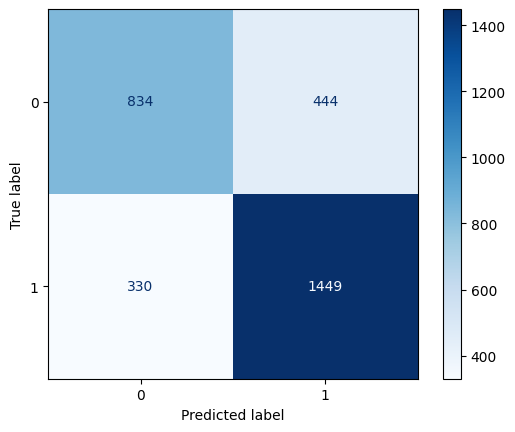

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Escolher melhor pelo AUC médio
melhor = max(resultados.keys(), key=lambda k: resultados[k]['roc_auc_mean'])
best_pipe_final = search_results[melhor].best_estimator_

# Treinar no conjunto de treino
best_pipe_final.fit(X_train, y_train)

# Predições
y_pred = best_pipe_final.predict(X_test)
y_proba = best_pipe_final.predict_proba(X_test)[:, 1]

# Resultados de teste
resultados_teste = {
    'Accuracy_test': accuracy_score(y_test, y_pred),
    'F1_test': f1_score(y_test, y_pred),
    'AUC_test': roc_auc_score(y_test, y_proba)
}

for chave, valor in resultados_teste.items():
    print(f"{chave}: {valor:.4f}")  

# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.show()

#### Explicação Global - SHAP

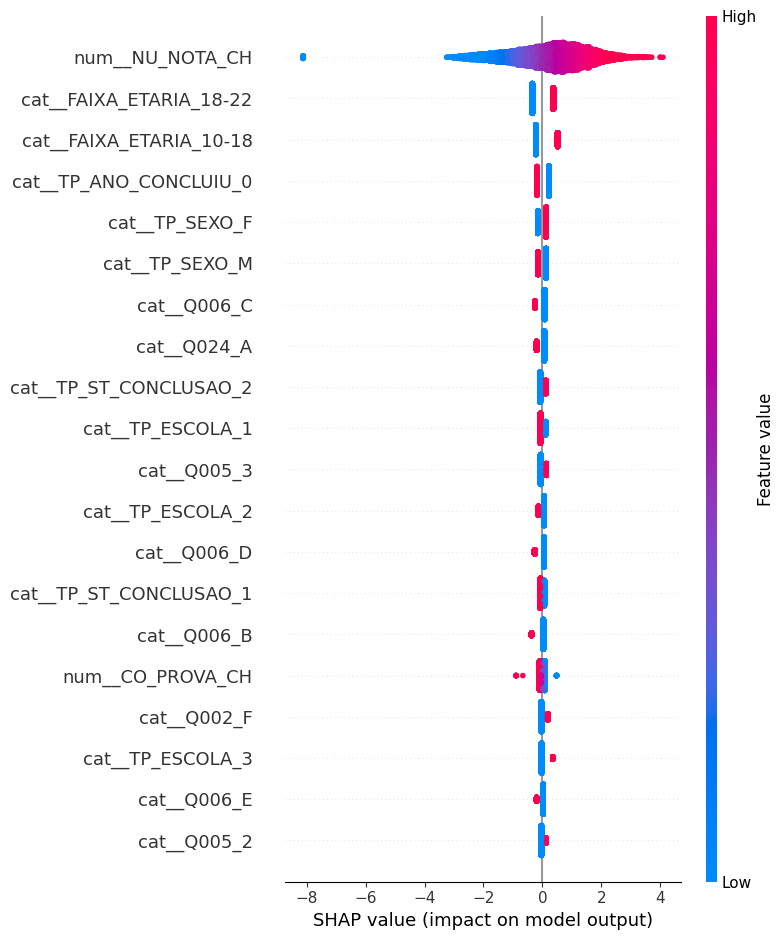

In [ ]:
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

## !!! Falta colocar nomes descritivos pras variáveis!!!

# Extrair o melhor modelo do pipeline otimizado
modelo_final = best_pipe_final.named_steps['modelo']

# Transformar os dados de treino com o pré-processador
X_train_transf = best_pipe_final.named_steps['preprocessamento'].fit_transform(X_train)

# Obter os nomes originais das variáveis
feature_names = best_pipe_final.named_steps['preprocessamento'].get_feature_names_out()

# Escolher o explainer adequado
if isinstance(modelo_final, RandomForestClassifier) or isinstance(modelo_final, DecisionTreeClassifier):
    explainer = shap.TreeExplainer(modelo_final)
    shap_values = explainer.shap_values(X_train_transf)

elif isinstance(modelo_final, LogisticRegression):
    masker = shap.maskers.Independent(X_train_transf)
    explainer = shap.LinearExplainer(modelo_final, masker)
    shap_values = explainer(X_train_transf)

else:
    explainer = shap.Explainer(modelo_final, X_train_transf)
    shap_values = explainer(X_train_transf)

# Plot resumo
shap.summary_plot(shap_values, X_train_transf, feature_names=feature_names, show=True)